In [1]:
import sklearn
import pandas as pd
import matplotlib.pyplot as plt
import sklearn.linear_model as lm
import sklearn.pipeline as pipe
import sklearn.preprocessing as pp
import sklearn.model_selection as ms
import sklearn.neighbors as n
import numpy as np
import sklearn.ensemble as rf
import tensorflow as tf
import keras

In [2]:
data = np.load("data/mnist/mnist.npz")
print(data)
xtrain = data["x_train"] / 255.0 # ou (x-127.5) / 127.5
xtest = data["x_test"] / 255.0
ytrain = data["y_train"]
ytest = data["y_test"]

NpzFile 'data/mnist/mnist.npz' with keys: x_test, x_train, y_train, y_test


In [3]:
xtrain = xtrain.reshape(-1, 28*28)
xtest = xtest.reshape(-1, 28*28)

In [4]:
ytrain = keras.utils.to_categorical(ytrain)
ytest = keras.utils.to_categorical(ytest)
ytrain.shape

(60000, 10)

In [5]:
model = keras.Sequential()
model.add(keras.layers.Input((xtrain.shape[1],)))
model.add(keras.layers.Dense(800, activation="relu"))
model.add(keras.layers.Dropout(0.1))
model.add(keras.layers.Dense(500, activation="relu"))
model.add(keras.layers.Dropout(0.1))
model.add(keras.layers.Dense(200, activation="relu"))
model.add(keras.layers.Dropout(0.1))
model.add(keras.layers.Dense(10, activation="softmax"))
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 800)                 │         628,000 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 800)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 500)                 │         400,500 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 500)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 200)                 │         100,200 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 200)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 10)                  │           2,010 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,130,710 (4.31 MB)

 Trainable params: 1,130,710 (4.31 MB)

 Non-trainable params: 0 (0.00 B)

In [6]:
model.compile(loss="categorical_crossentropy", metrics=["accuracy"])
model.fit(xtrain, ytrain, epochs=10, validation_split=0.2, batch_size=100)


Epoch 1/10
480/480 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9154 - loss: 0.2711 - val_accuracy: 0.9622 - val_loss: 0.1211
Epoch 2/10
480/480 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.9689 - loss: 0.1032 - val_accuracy: 0.9670 - val_loss: 0.1165
Epoch 3/10
480/480 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - accuracy: 0.9780 - loss: 0.0723 - val_accuracy: 0.9720 - val_loss: 0.0981
Epoch 4/10
480/480 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - accuracy: 0.9832 - loss: 0.0567 - val_accuracy: 0.9743 - val_loss: 0.0984
Epoch 5/10
480/480 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9875 - loss: 0.0418 - val_accuracy: 0.9755 - val_loss: 0.1038
Epoch 6/10
480/480 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9891 - loss: 0.0364 - val_accuracy: 0.9772 - val_loss: 0.0908
Epoch 7/10
480/480 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9912 - loss: 0.0281 - val_accuracy: 0.9793 - val_loss: 0.0895
Epoch 8/10
480/480 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9923 - loss: 0.0240 - val_accuracy: 

In [7]:
model.evaluate(xtest, ytest)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9802 - loss: 0.0983


[0.09833213686943054, 0.9801999926567078]

In [8]:
model.save("data/mnist/mlp.h5")

In [9]:
ypred = np.argmax(model.predict(xtest), axis=1)
xtest.shape, ypred

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


((10000, 784), array([7, 2, 1, ..., 4, 5, 6], shape=(10000,)))

In [10]:
select = np.random.randint(xtest.shape[0], size=12)
xtest = xtest.reshape(-1, 28, 28)

In [11]:
ytest = data["y_test"]
errors = ytest != ypred
xerrors = xtest[errors]
yerrors = ypred[errors]
yerrors

array([2, 7, 3, 0, 9, 2, 2, 1, 3, 4, 9, 9, 9, 3, 9, 9, 0, 3, 5, 2, 6, 5,
       2, 4, 9, 3, 1, 9, 7, 3, 9, 6, 3, 3, 9, 5, 7, 6, 3, 0, 3, 5, 3, 7,
       2, 3, 2, 3, 4, 8, 9, 3, 3, 8, 9, 9, 0, 7, 0, 9, 9, 1, 1, 9, 3, 8,
       1, 3, 1, 4, 4, 9, 4, 3, 1, 0, 1, 3, 7, 5, 5, 1, 2, 3, 3, 3, 9, 9,
       0, 3, 1, 4, 2, 0, 3, 3, 9, 3, 8, 6, 2, 3, 3, 3, 2, 5, 1, 4, 1, 2,
       3, 3, 2, 8, 7, 7, 8, 7, 5, 3, 3, 3, 3, 3, 9, 7, 7, 5, 0, 9, 3, 7,
       8, 3, 4, 9, 6, 8, 3, 1, 5, 8, 3, 2, 9, 3, 8, 3, 9, 9, 3, 9, 9, 9,
       3, 9, 3, 9, 3, 3, 1, 7, 7, 5, 8, 3, 7, 6, 4, 3, 3, 8, 7, 3, 0, 1,
       9, 6, 9, 6, 9, 9, 2, 2, 5, 3, 3, 4, 1, 7, 3, 6, 7, 0, 0, 1, 3, 8])

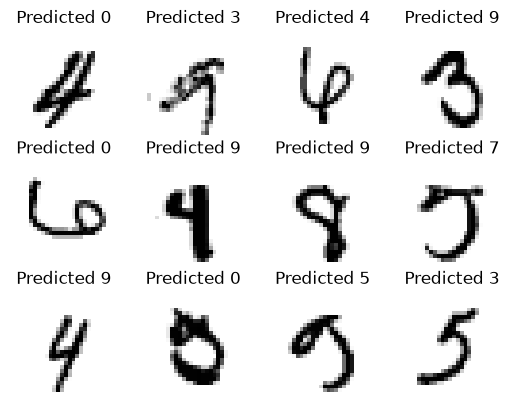

In [12]:
select = np.random.randint(xerrors.shape[0], size=12)
for index, value in enumerate(select):
    plt.subplot(3,4, index + 1)
    plt.axis("off")
    plt.imshow(xerrors[value], cmap=plt.cm.gray_r)
    plt.title(f"Predicted {yerrors[value]}")
plt.show()